KNN
**(Setosa, Versicolor, Virginica)**

In [4]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix
from sklearn.metrics import f1_score
from sklearn.metrics import accuracy_score,confusion_matrix,ConfusionMatrixDisplay
import matplotlib.pyplot as plt


In [6]:
# 2. Load the dataset
data = load_iris()
x = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target) # setosa, 1 = versicolor, 2 = virginica
x


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [9]:
print(f"Shape of data: {x.shape}")
print(f"Classes: {data.target_names}")
print(f"Count of each class:\n{y.value_counts()}")



Shape of data: (150, 4)
Classes: ['setosa' 'versicolor' 'virginica']
Count of each class:
0    50
1    50
2    50
Name: count, dtype: int64


In [11]:
# 3. Split into training and testing sets (80% train, 20% test)
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=42, stratify = y)

In [13]:
#4. Feature scaling (KNN uses distance, so scaling is important)
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [18]:
#5. Create and train the KNN model
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train, y_train)

KNeighborsClassifier()

In [20]:
#6. Predict on test data
y_pred = knn.predict(x_test)

In [22]:
#7. Evaluating the model
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy*100:.2f}%")

Accuracy: 93.33%


In [24]:
cm = confusion_matrix(y_test,  y_pred)
print(f"Confusion Matrix:\n{cm}")

Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]


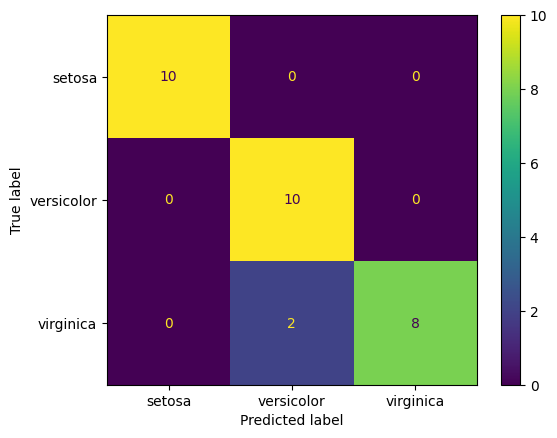

In [25]:
ConfusionMatrixDisplay(cm, display_labels=data.target_names).plot()
